# FreshBasket Retail — Customer Churn Prediction

## 01. Data Quality Audit & Exploratory Data Analysis

### Business Objective

FreshBasket Retail wants to identify loyalty-program customers who are at
risk of churn before they stop purchasing.

The objective of this project is to build a customer-level churn prediction
system using historical customer behaviour, engagement, support activity,
and customer profile information.

### Dataset

The dataset contains three primary tables:

- `fb Customer Profile`
- `fb Monthly Activity`
- `fb Churn Label`

The observation period is January 2023 through June 2024.

### Critical Leakage Constraint

The churn label is based on customer activity during the final three months:

**April 2024 – June 2024**

Therefore, predictive features must only use information that would have
been available before the label window.

**Feature cutoff: March 31, 2024**

No April, May, or June 2024 activity may be used to construct predictive
features.

In [313]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [314]:
# ============================================================
# 2. PROJECT PATHS
# ============================================================

# The notebook is inside:
# FreshBasket_Churn/notebooks/
#
# Therefore, parent directory = FreshBasket_Churn/

PROJECT_ROOT = Path.cwd().parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("PROJECT ROOT:")
print(PROJECT_ROOT)

print("\nRAW DATA DIRECTORY:")
print(RAW_DATA_DIR)

print("\nFILES IN RAW DATA DIRECTORY:")

for file in RAW_DATA_DIR.iterdir():
    print(" -", file.name)

PROJECT ROOT:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn

RAW DATA DIRECTORY:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\data\raw

FILES IN RAW DATA DIRECTORY:
 - FreshBasket_Loyalty_Churn_Dataset.xlsx


In [315]:
# ============================================================
# 3. LOCATE RAW EXCEL FILE
# ============================================================

excel_files = list(RAW_DATA_DIR.glob("*.xlsx"))

if len(excel_files) == 0:
    raise FileNotFoundError(
        "No Excel (.xlsx) file was found inside data/raw/"
    )

print(f"Found {len(excel_files)} Excel file(s):\n")

for file in excel_files:
    print(" -", file.name)

# Use the first Excel file for now
EXCEL_PATH = excel_files[0]

print("\nUsing:")
print(EXCEL_PATH)

Found 1 Excel file(s):

 - FreshBasket_Loyalty_Churn_Dataset.xlsx

Using:
c:\Users\shrey\Downloads\FreshBasket_Churn_Project_Structure\FreshBasket_Churn\data\raw\FreshBasket_Loyalty_Churn_Dataset.xlsx


In [316]:
# ============================================================
# 4. INSPECT WORKBOOK
# ============================================================

excel = pd.ExcelFile(EXCEL_PATH)

print("Available sheets:\n")

for i, sheet in enumerate(excel.sheet_names, start=1):
    print(f"{i}. {sheet}")

Available sheets:

1. Glossary
2. fb Customer Profile
3. fb Monthly Activity
4. fb Churn Label
5. Data Dictionary


In [269]:
# ============================================================
# 5. LOAD PRIMARY DATA TABLES
# ============================================================

# The workbook has a title row above the actual column headers.
# Therefore, header=1 means:
#   Row 1 in Excel -> ignored
#   Row 2 in Excel -> used as column names
#   Row 3 onward   -> actual data

customer_profile = pd.read_excel(
    EXCEL_PATH,
    sheet_name="fb Customer Profile",
    header=1
)

monthly_activity = pd.read_excel(
    EXCEL_PATH,
    sheet_name="fb Monthly Activity",
    header=1
)

churn_label = pd.read_excel(
    EXCEL_PATH,
    sheet_name="fb Churn Label",
    header=1
)

print("DATASETS LOADED\n")

print("Customer Profile :", customer_profile.shape)
print("Monthly Activity  :", monthly_activity.shape)
print("Churn Label       :", churn_label.shape)

DATASETS LOADED

Customer Profile : (2608, 10)
Monthly Activity  : (28073, 12)
Churn Label       : (2605, 6)


In [270]:
# ============================================================
# 6. VERIFY COLUMN NAMES
# ============================================================

print("Customer Profile columns:")
print(customer_profile.columns.tolist())

print("\nMonthly Activity columns:")
print(monthly_activity.columns.tolist())

print("\nChurn Label columns:")
print(churn_label.columns.tolist())

Customer Profile columns:
['CUSTOMER_ID', 'SIGNUP_DATE', 'AGE', 'GENDER', 'CITY', 'MEMBERSHIP_TIER', 'MARKETING_OPT_IN', 'PREFERRED_STORE_ID', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER']

Monthly Activity columns:
['CUSTOMER_ID', 'MONTH', 'TRANSACTIONS', 'TOTAL_SPEND', 'AVG_BASKET_VALUE', 'DISTINCT_CATEGORIES', 'PROMO_TXN_PCT', 'APP_SESSIONS', 'EMAILS_OPENED', 'COUPONS_REDEEMED', 'SUPPORT_TICKETS', 'COMPLAINT_FLAG']

Churn Label columns:
['CUSTOMER_ID', 'OBSERVATION_END_DATE', 'LAST_PURCHASE_DATE', 'MONTHS_OBSERVED', 'INSUFFICIENT_HISTORY_FLAG', 'CHURNED']


In [271]:
# ============================================================
# 7. COLUMN AND DATA TYPE INSPECTION
# ============================================================

print("=" * 70)
print("CUSTOMER PROFILE")
print("=" * 70)

print(customer_profile.dtypes)

print("\n" + "=" * 70)
print("MONTHLY ACTIVITY")
print("=" * 70)

print(monthly_activity.dtypes)

print("\n" + "=" * 70)
print("CHURN LABEL")
print("=" * 70)

print(churn_label.dtypes)

CUSTOMER PROFILE
CUSTOMER_ID                       int64
SIGNUP_DATE              datetime64[ns]
AGE                             float64
GENDER                           object
CITY                             object
MEMBERSHIP_TIER                  object
MARKETING_OPT_IN                  int64
PREFERRED_STORE_ID                int64
PREFERRED_CATEGORY               object
HOME_STORE_PRICE_TIER            object
dtype: object

MONTHLY ACTIVITY
CUSTOMER_ID                     int64
MONTH                  datetime64[ns]
TRANSACTIONS                    int64
TOTAL_SPEND                   float64
AVG_BASKET_VALUE              float64
DISTINCT_CATEGORIES             int64
PROMO_TXN_PCT                 float64
APP_SESSIONS                    int64
EMAILS_OPENED                   int64
COUPONS_REDEEMED                int64
SUPPORT_TICKETS                 int64
COMPLAINT_FLAG                  int64
dtype: object

CHURN LABEL
CUSTOMER_ID                           int64
OBSERVATION_END_DATE    

In [272]:
# ============================================================
# 8. COLUMN NAMES
# ============================================================

print("Customer Profile columns:")
print(customer_profile.columns.tolist())

print("\nMonthly Activity columns:")
print(monthly_activity.columns.tolist())

print("\nChurn Label columns:")
print(churn_label.columns.tolist())

Customer Profile columns:
['CUSTOMER_ID', 'SIGNUP_DATE', 'AGE', 'GENDER', 'CITY', 'MEMBERSHIP_TIER', 'MARKETING_OPT_IN', 'PREFERRED_STORE_ID', 'PREFERRED_CATEGORY', 'HOME_STORE_PRICE_TIER']

Monthly Activity columns:
['CUSTOMER_ID', 'MONTH', 'TRANSACTIONS', 'TOTAL_SPEND', 'AVG_BASKET_VALUE', 'DISTINCT_CATEGORIES', 'PROMO_TXN_PCT', 'APP_SESSIONS', 'EMAILS_OPENED', 'COUPONS_REDEEMED', 'SUPPORT_TICKETS', 'COMPLAINT_FLAG']

Churn Label columns:
['CUSTOMER_ID', 'OBSERVATION_END_DATE', 'LAST_PURCHASE_DATE', 'MONTHS_OBSERVED', 'INSUFFICIENT_HISTORY_FLAG', 'CHURNED']


In [273]:
# ============================================================
# 9. UNIQUE CUSTOMER COUNTS
# ============================================================

print("CUSTOMER PROFILE")
print("Rows:", len(customer_profile))
print("Unique customers:", customer_profile["CUSTOMER_ID"].nunique())

print("\nMONTHLY ACTIVITY")
print("Rows:", len(monthly_activity))
print("Unique customers:", monthly_activity["CUSTOMER_ID"].nunique())

print("\nCHURN LABEL")
print("Rows:", len(churn_label))
print("Unique customers:", churn_label["CUSTOMER_ID"].nunique())

CUSTOMER PROFILE
Rows: 2608
Unique customers: 2600

MONTHLY ACTIVITY
Rows: 28073
Unique customers: 2594

CHURN LABEL
Rows: 2605
Unique customers: 2600


In [274]:
# ============================================================
# 10. DUPLICATE ANALYSIS
# ============================================================

print("=" * 70)
print("DUPLICATE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# CUSTOMER PROFILE
# ------------------------------------------------------------

print("\nCUSTOMER PROFILE")

print(
    "Full duplicate rows:",
    customer_profile.duplicated().sum()
)

print(
    "Duplicate CUSTOMER_IDs:",
    customer_profile["CUSTOMER_ID"].duplicated().sum()
)

# ------------------------------------------------------------
# MONTHLY ACTIVITY
# ------------------------------------------------------------

print("\nMONTHLY ACTIVITY")

print(
    "Full duplicate rows:",
    monthly_activity.duplicated().sum()
)

print(
    "Duplicate CUSTOMER_ID + MONTH:",
    monthly_activity.duplicated(
        subset=["CUSTOMER_ID", "MONTH"]
    ).sum()
)

# ------------------------------------------------------------
# CHURN LABEL
# ------------------------------------------------------------

print("\nCHURN LABEL")

print(
    "Full duplicate rows:",
    churn_label.duplicated().sum()
)

print(
    "Duplicate CUSTOMER_IDs:",
    churn_label["CUSTOMER_ID"].duplicated().sum()
)

DUPLICATE ANALYSIS

CUSTOMER PROFILE
Full duplicate rows: 8
Duplicate CUSTOMER_IDs: 8

MONTHLY ACTIVITY
Full duplicate rows: 58
Duplicate CUSTOMER_ID + MONTH: 60

CHURN LABEL
Full duplicate rows: 5
Duplicate CUSTOMER_IDs: 5


In [275]:
# ============================================================
# 11. SHOW DUPLICATE RECORDS
# ============================================================

print("CUSTOMER PROFILE DUPLICATE CUSTOMER IDs")
profile_dup_ids = customer_profile[
    customer_profile["CUSTOMER_ID"].duplicated(keep=False)
].sort_values("CUSTOMER_ID")

display(profile_dup_ids)


print("\nMONTHLY ACTIVITY DUPLICATE CUSTOMER-MONTH RECORDS")

activity_dup = monthly_activity[
    monthly_activity.duplicated(
        subset=["CUSTOMER_ID", "MONTH"],
        keep=False
    )
].sort_values(["CUSTOMER_ID", "MONTH"])

display(activity_dup)


print("\nCHURN LABEL DUPLICATE CUSTOMER IDs")

churn_dup_ids = churn_label[
    churn_label["CUSTOMER_ID"].duplicated(keep=False)
].sort_values("CUSTOMER_ID")

display(churn_dup_ids)

CUSTOMER PROFILE DUPLICATE CUSTOMER IDs


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
78,500079,2023-06-09,63.0,F,Spokane,Silver,1,112,Produce,Value
2606,500079,2023-06-09,63.0,F,Spokane,Silver,1,112,Produce,Value
2607,500205,2021-09-03,35.0,M,Tulsa,Gold,1,125,Household,Value
204,500205,2021-09-03,35.0,M,Tulsa,Gold,1,125,Household,Value
452,500453,2021-12-21,63.0,F,Nashville,Silver,0,101,Beverages,Mainstream
2602,500453,2021-12-21,63.0,F,Nashville,Silver,0,101,Beverages,Mainstream
2605,501209,2023-10-16,35.0,M,Denver,Gold,1,115,Produce,Mainstream
1208,501209,2023-10-16,35.0,M,Denver,Gold,1,115,Produce,Mainstream
2604,501216,2023-02-04,61.0,M,Portland,Silver,1,140,Produce,Value
1215,501216,2023-02-04,61.0,M,Portland,Silver,1,140,Produce,Value



MONTHLY ACTIVITY DUPLICATE CUSTOMER-MONTH RECORDS


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
8608,500029,2023-09-01,3,36.54,12.18,3,0.34,2,0,0,0,0
23380,500029,2023-09-01,3,36.54,12.18,3,0.34,2,0,0,0,0
2452,500045,2023-02-01,5,177.54,35.51,3,0.51,2,3,0,0,0
25713,500045,2023-02-01,5,177.54,35.51,3,0.51,2,3,0,0,0
450,500047,2023-02-01,7,207.53,29.65,4,0.21,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
13754,502413,2023-08-01,7,278.52,39.79,5,0.16,3,1,1,0,0
11908,502582,2023-09-01,1,31.39,31.39,2,0.24,0,0,1,0,0
24103,502582,2023-09-01,1,31.39,31.39,2,0.24,0,0,1,0,0
22322,502582,2023-10-01,2,63.22,31.61,0,0.44,5,3,0,0,0



CHURN LABEL DUPLICATE CUSTOMER IDs


,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
194,500195,2024-06-30,2024-06-01,8,0,0
2602,500195,2024-06-30,2024-06-01,8,0,0
767,500768,2024-06-30,2023-10-01,12,0,1
2604,500768,2024-06-30,2023-10-01,12,0,1
2601,500977,2024-06-30,2023-09-01,6,0,1
976,500977,2024-06-30,2023-09-01,6,0,1
2603,501725,2024-06-30,2024-06-01,18,0,0
1724,501725,2024-06-30,2024-06-01,18,0,0
1958,501959,2024-06-30,2023-12-01,13,0,1
2600,501959,2024-06-30,2023-12-01,13,0,1


In [276]:
# ============================================================
# 12. MISSING VALUE AUDIT
# ============================================================

def missing_report(df, name):

    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": (
            df.isna().mean() * 100
        ).round(2)
    })

    report = report[
        report["missing_count"] > 0
    ].sort_values(
        "missing_count",
        ascending=False
    )

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    if report.empty:
        print("No missing values found.")
    else:
        display(report)

    return report


profile_missing = missing_report(
    customer_profile,
    "CUSTOMER PROFILE"
)

activity_missing = missing_report(
    monthly_activity,
    "MONTHLY ACTIVITY"
)

churn_missing = missing_report(
    churn_label,
    "CHURN LABEL"
)


CUSTOMER PROFILE


,missing_count,missing_pct
HOME_STORE_PRICE_TIER,130,4.98
AGE,78,2.99
GENDER,52,1.99



MONTHLY ACTIVITY
No missing values found.

CHURN LABEL


,missing_count,missing_pct
LAST_PURCHASE_DATE,120,4.61


In [277]:
# ============================================================
# 13. NUMERIC DATA QUALITY CHECK
# ============================================================

print("=" * 70)
print("NUMERIC DATA QUALITY")
print("=" * 70)

# Customer Profile
print("\nAGE")
print("Negative ages:",
      (customer_profile["AGE"] < 0).sum())

print("Age below 18:",
      (customer_profile["AGE"] < 18).sum())

print("Age above 100:",
      (customer_profile["AGE"] > 100).sum())


# Monthly Activity
print("\nTRANSACTIONS")
print("Negative transactions:",
      (monthly_activity["TRANSACTIONS"] < 0).sum())

print("\nTOTAL SPEND")
print("Negative spend:",
      (monthly_activity["TOTAL_SPEND"] < 0).sum())

print("\nAVG BASKET VALUE")
print("Negative basket values:",
      (monthly_activity["AVG_BASKET_VALUE"] < 0).sum())

print("\nPROMO TXN PCT")
print("Below 0:",
      (monthly_activity["PROMO_TXN_PCT"] < 0).sum())

print("Above 1:",
      (monthly_activity["PROMO_TXN_PCT"] > 1).sum())

print("\nCOMPLAINT FLAG")
print(
    monthly_activity["COMPLAINT_FLAG"]
    .value_counts(dropna=False)
)

NUMERIC DATA QUALITY

AGE
Negative ages: 0
Age below 18: 0
Age above 100: 0

TRANSACTIONS
Negative transactions: 0

TOTAL SPEND
Negative spend: 24

AVG BASKET VALUE
Negative basket values: 0

PROMO TXN PCT
Below 0: 0
Above 1: 0

COMPLAINT FLAG
COMPLAINT_FLAG
0    26894
1     1179
Name: count, dtype: int64


In [278]:
# ============================================================
# 14. CHURN TARGET DISTRIBUTION
# ============================================================

churn_counts = (
    churn_label["CHURNED"]
    .value_counts(dropna=False)
)

churn_percentages = (
    churn_label["CHURNED"]
    .value_counts(
        normalize=True,
        dropna=False
    )
    .mul(100)
    .round(2)
)

target_summary = pd.DataFrame({
    "count": churn_counts,
    "percentage": churn_percentages
})

display(target_summary)

,count,percentage
CHURNED,,
0,1784,68.48
1,821,31.52


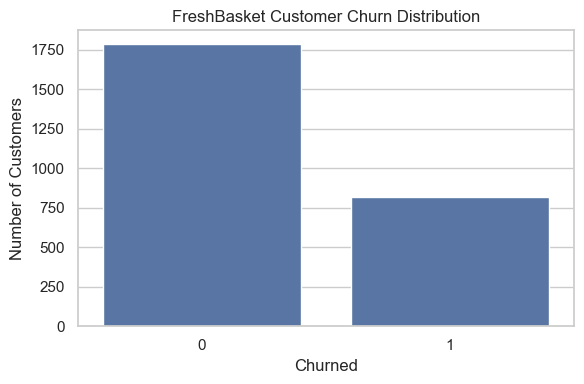

In [279]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=churn_label,
    x="CHURNED"
)

plt.title("FreshBasket Customer Churn Distribution")
plt.xlabel("Churned")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [280]:
# ============================================================
# DUPLICATE ANALYSIS
# ============================================================

print("=" * 70)
print("DUPLICATE ANALYSIS")
print("=" * 70)

print("\nCUSTOMER PROFILE")
print("Full duplicate rows:", customer_profile.duplicated().sum())
print(
    "Duplicate CUSTOMER_IDs:",
    customer_profile["CUSTOMER_ID"].duplicated().sum()
)

print("\nMONTHLY ACTIVITY")
print("Full duplicate rows:", monthly_activity.duplicated().sum())
print(
    "Duplicate CUSTOMER_ID + MONTH:",
    monthly_activity.duplicated(
        subset=["CUSTOMER_ID", "MONTH"]
    ).sum()
)

print("\nCHURN LABEL")
print("Full duplicate rows:", churn_label.duplicated().sum())
print(
    "Duplicate CUSTOMER_IDs:",
    churn_label["CUSTOMER_ID"].duplicated().sum()
)

DUPLICATE ANALYSIS

CUSTOMER PROFILE
Full duplicate rows: 8
Duplicate CUSTOMER_IDs: 8

MONTHLY ACTIVITY
Full duplicate rows: 58
Duplicate CUSTOMER_ID + MONTH: 60

CHURN LABEL
Full duplicate rows: 5
Duplicate CUSTOMER_IDs: 5


In [281]:
print("=" * 70)
print("CUSTOMER PROFILE DUPLICATES")
print("=" * 70)

profile_dup_ids = customer_profile[
    customer_profile["CUSTOMER_ID"].duplicated(keep=False)
].sort_values("CUSTOMER_ID")

display(profile_dup_ids)


print("=" * 70)
print("MONTHLY ACTIVITY DUPLICATE CUSTOMER-MONTHS")
print("=" * 70)

activity_dup = monthly_activity[
    monthly_activity.duplicated(
        subset=["CUSTOMER_ID", "MONTH"],
        keep=False
    )
].sort_values(["CUSTOMER_ID", "MONTH"])

display(activity_dup)


print("=" * 70)
print("CHURN LABEL DUPLICATES")
print("=" * 70)

churn_dup_ids = churn_label[
    churn_label["CUSTOMER_ID"].duplicated(keep=False)
].sort_values("CUSTOMER_ID")

display(churn_dup_ids)

CUSTOMER PROFILE DUPLICATES


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
78,500079,2023-06-09,63.0,F,Spokane,Silver,1,112,Produce,Value
2606,500079,2023-06-09,63.0,F,Spokane,Silver,1,112,Produce,Value
2607,500205,2021-09-03,35.0,M,Tulsa,Gold,1,125,Household,Value
204,500205,2021-09-03,35.0,M,Tulsa,Gold,1,125,Household,Value
452,500453,2021-12-21,63.0,F,Nashville,Silver,0,101,Beverages,Mainstream
2602,500453,2021-12-21,63.0,F,Nashville,Silver,0,101,Beverages,Mainstream
2605,501209,2023-10-16,35.0,M,Denver,Gold,1,115,Produce,Mainstream
1208,501209,2023-10-16,35.0,M,Denver,Gold,1,115,Produce,Mainstream
2604,501216,2023-02-04,61.0,M,Portland,Silver,1,140,Produce,Value
1215,501216,2023-02-04,61.0,M,Portland,Silver,1,140,Produce,Value


MONTHLY ACTIVITY DUPLICATE CUSTOMER-MONTHS


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
8608,500029,2023-09-01,3,36.54,12.18,3,0.34,2,0,0,0,0
23380,500029,2023-09-01,3,36.54,12.18,3,0.34,2,0,0,0,0
2452,500045,2023-02-01,5,177.54,35.51,3,0.51,2,3,0,0,0
25713,500045,2023-02-01,5,177.54,35.51,3,0.51,2,3,0,0,0
450,500047,2023-02-01,7,207.53,29.65,4,0.21,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
13754,502413,2023-08-01,7,278.52,39.79,5,0.16,3,1,1,0,0
11908,502582,2023-09-01,1,31.39,31.39,2,0.24,0,0,1,0,0
24103,502582,2023-09-01,1,31.39,31.39,2,0.24,0,0,1,0,0
22322,502582,2023-10-01,2,63.22,31.61,0,0.44,5,3,0,0,0


CHURN LABEL DUPLICATES


,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
194,500195,2024-06-30,2024-06-01,8,0,0
2602,500195,2024-06-30,2024-06-01,8,0,0
767,500768,2024-06-30,2023-10-01,12,0,1
2604,500768,2024-06-30,2023-10-01,12,0,1
2601,500977,2024-06-30,2023-09-01,6,0,1
976,500977,2024-06-30,2023-09-01,6,0,1
2603,501725,2024-06-30,2024-06-01,18,0,0
1724,501725,2024-06-30,2024-06-01,18,0,0
1958,501959,2024-06-30,2023-12-01,13,0,1
2600,501959,2024-06-30,2023-12-01,13,0,1


In [282]:
# Find CUSTOMER_ID + MONTH combinations that occur more than once
dup_groups = (
    monthly_activity
    .groupby(["CUSTOMER_ID", "MONTH"])
    .size()
    .reset_index(name="row_count")
)

dup_groups = dup_groups[dup_groups["row_count"] > 1]

print("Duplicate customer-month groups:", len(dup_groups))
display(dup_groups)

Duplicate customer-month groups: 60


,CUSTOMER_ID,MONTH,row_count
364,500029,2023-09-01,2
527,500045,2023-02-01,2
551,500047,2023-02-01,2
1408,500124,2023-09-01,2
1637,500143,2023-08-01,2
2135,500190,2023-04-01,2
3308,500300,2024-05-01,2
4184,500379,2023-01-01,2
4281,500387,2023-04-01,2
5126,500464,2023-11-01,2


In [283]:
# Check whether duplicated customer-month groups contain conflicting values
conflicting_groups = []

for _, row in dup_groups.iterrows():

    customer_id = row["CUSTOMER_ID"]
    month = row["MONTH"]

    group = monthly_activity[
        (monthly_activity["CUSTOMER_ID"] == customer_id) &
        (monthly_activity["MONTH"] == month)
    ]

    # Number of unique values in each column
    nunique = group.nunique()

    # If any column other than CUSTOMER_ID/MONTH differs,
    # this is a non-identical duplicate
    varying_columns = nunique[nunique > 1].index.tolist()

    if varying_columns:
        conflicting_groups.append({
            "CUSTOMER_ID": customer_id,
            "MONTH": month,
            "varying_columns": varying_columns
        })

print("Non-identical duplicate customer-month groups:",
      len(conflicting_groups))

display(pd.DataFrame(conflicting_groups))

Non-identical duplicate customer-month groups: 2


,CUSTOMER_ID,MONTH,varying_columns
0,501780,2024-05-01,[TOTAL_SPEND]
1,502065,2023-04-01,[TOTAL_SPEND]


In [284]:
for item in conflicting_groups:

    customer_id = item["CUSTOMER_ID"]
    month = item["MONTH"]

    print("=" * 70)
    print(f"CUSTOMER_ID = {customer_id}, MONTH = {month}")
    print("=" * 70)

    display(
        monthly_activity[
            (monthly_activity["CUSTOMER_ID"] == customer_id) &
            (monthly_activity["MONTH"] == month)
        ]
    )

CUSTOMER_ID = 501780, MONTH = 2024-05-01 00:00:00


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
14414,501780,2024-05-01,3,116.18,38.73,2,0.07,6,1,0,0,0
16384,501780,2024-05-01,3,-116.18,38.73,2,0.07,6,1,0,0,0


CUSTOMER_ID = 502065, MONTH = 2023-04-01 00:00:00


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
15432,502065,2023-04-01,3,-70.32,23.44,2,0.22,0,2,1,0,0
26567,502065,2023-04-01,3,70.32,23.44,2,0.22,0,2,1,0,0


In [285]:
conflict_ids = [
    (501780, "2024-05-01"),
    (502065, "2023-04-01")
]

for customer_id, month in conflict_ids:

    print("=" * 80)
    print(f"CUSTOMER_ID: {customer_id} | MONTH: {month}")
    print("=" * 80)

    display(
        monthly_activity[
            (monthly_activity["CUSTOMER_ID"] == customer_id) &
            (monthly_activity["MONTH"] == month)
        ]
    )

CUSTOMER_ID: 501780 | MONTH: 2024-05-01


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
14414,501780,2024-05-01,3,116.18,38.73,2,0.07,6,1,0,0,0
16384,501780,2024-05-01,3,-116.18,38.73,2,0.07,6,1,0,0,0


CUSTOMER_ID: 502065 | MONTH: 2023-04-01


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
15432,502065,2023-04-01,3,-70.32,23.44,2,0.22,0,2,1,0,0
26567,502065,2023-04-01,3,70.32,23.44,2,0.22,0,2,1,0,0


In [286]:
print("=" * 70)
print("NEGATIVE TOTAL_SPEND AUDIT")
print("=" * 70)

negative_spend = monthly_activity[
    monthly_activity["TOTAL_SPEND"] < 0
]

print("Negative TOTAL_SPEND rows:", len(negative_spend))
print(
    "Negative TOTAL_SPEND customer-months:",
    negative_spend[["CUSTOMER_ID", "MONTH"]].drop_duplicates().shape[0]
)

display(
    negative_spend[
        [
            "CUSTOMER_ID",
            "MONTH",
            "TRANSACTIONS",
            "TOTAL_SPEND",
            "AVG_BASKET_VALUE",
            "DISTINCT_CATEGORIES"
        ]
    ].head(20)
)

NEGATIVE TOTAL_SPEND AUDIT
Negative TOTAL_SPEND rows: 24
Negative TOTAL_SPEND customer-months: 24


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES
731,501082,2023-09-01,10,-226.93,22.69,4
772,500973,2024-02-01,1,-31.05,31.05,2
2765,501679,2024-03-01,7,-249.21,35.60,3
4478,500160,2023-01-01,2,-89.01,44.50,4
4646,501401,2023-05-01,4,-67.01,16.75,5
5344,501769,2023-03-01,1,-52.38,52.38,3
6119,501344,2023-12-01,7,-237.96,33.99,2
7028,501222,2023-04-01,5,-101.39,20.28,1
7572,502227,2024-02-01,5,-196.53,39.31,5
7964,501597,2023-08-01,3,-138.85,46.28,4


In [287]:
def missing_report(df, name):
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2)
    })

    report = report[
        report["missing_count"] > 0
    ].sort_values("missing_count", ascending=False)

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    if report.empty:
        print("No missing values found.")
    else:
        display(report)

    return report


profile_missing = missing_report(
    customer_profile,
    "CUSTOMER PROFILE"
)

activity_missing = missing_report(
    monthly_activity,
    "MONTHLY ACTIVITY"
)

churn_missing = missing_report(
    churn_label,
    "CHURN LABEL"
)


CUSTOMER PROFILE


,missing_count,missing_pct
HOME_STORE_PRICE_TIER,130,4.98
AGE,78,2.99
GENDER,52,1.99



MONTHLY ACTIVITY
No missing values found.

CHURN LABEL


,missing_count,missing_pct
LAST_PURCHASE_DATE,120,4.61


In [288]:
print("=" * 70)
print("MISSING VALUE INVESTIGATION")
print("=" * 70)

# ---------------------------------------------------------
# 1. Customer Profile
# ---------------------------------------------------------

print("\nCUSTOMER PROFILE")
print("-" * 70)

print("Missing AGE:")
display(
    customer_profile[
        customer_profile["AGE"].isna()
    ].head(10)
)

print("Missing GENDER:")
display(
    customer_profile[
        customer_profile["GENDER"].isna()
    ].head(10)
)

print("Missing HOME_STORE_PRICE_TIER:")
display(
    customer_profile[
        customer_profile["HOME_STORE_PRICE_TIER"].isna()
    ].head(10)
)


# ---------------------------------------------------------
# 2. Churn Label
# ---------------------------------------------------------

print("\nCHURN LABEL")
print("-" * 70)

print(
    "Missing LAST_PURCHASE_DATE by INSUFFICIENT_HISTORY_FLAG:"
)

display(
    churn_label[
        churn_label["LAST_PURCHASE_DATE"].isna()
    ]["INSUFFICIENT_HISTORY_FLAG"]
    .value_counts(dropna=False)
)


print("\nMissing LAST_PURCHASE_DATE by CHURNED:")

display(
    churn_label[
        churn_label["LAST_PURCHASE_DATE"].isna()
    ]["CHURNED"]
    .value_counts(dropna=False)
)

MISSING VALUE INVESTIGATION

CUSTOMER PROFILE
----------------------------------------------------------------------
Missing AGE:


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
55,500056,2024-01-10,NaN,M,Spokane,Gold,1,106,Bakery,Upscale
95,500096,2023-02-17,NaN,F,Madison,Platinum,0,134,Dairy,Value
97,500098,2023-01-08,NaN,F,Raleigh,Gold,1,126,Beverages,Mainstream
110,500111,2022-11-27,NaN,M,Denver,Platinum,0,119,Household,Mainstream
161,500162,2024-04-16,NaN,Other,Tulsa,Gold,0,114,Dairy,Mainstream
201,500202,2021-12-15,NaN,M,Madison,Silver,1,138,Bakery,Value
242,500243,2023-05-18,NaN,F,Spokane,Silver,1,117,Household,Upscale
319,500320,2022-08-12,NaN,F,Denver,SILVER,1,130,Beverages,Mainstream
385,500386,2021-07-23,NaN,F,Austin,Silver,1,118,Snacks,Mainstream
492,500493,2023-06-10,NaN,F,Austin,Platinum,0,132,Produce,Value


Missing GENDER:


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
2,500003,2021-03-31,53.0,NaN,Tulsa,Gold,0,119,Frozen Foods,Mainstream
25,500026,2024-02-23,23.0,NaN,Portland,Gold,1,114,Dairy,Mainstream
79,500080,2023-11-14,60.0,NaN,Denver,Platinum,1,134,Dairy,Value
114,500115,2022-01-11,56.0,NaN,Austin,Gold,1,102,Dairy,NaN
147,500148,2021-05-06,34.0,NaN,Madison,Silver,0,120,Personal Care,Upscale
231,500232,2021-03-23,41.0,NaN,Austin,Silver,0,138,Personal Care,Value
276,500277,2021-06-20,23.0,NaN,Madison,Gold,1,112,Dairy,Value
334,500335,2022-11-02,71.0,NaN,Nashville,Silver,1,123,Bakery,Mainstream
402,500403,2023-10-26,55.0,NaN,Columbus,Silver,0,133,Beverages,Value
538,500539,2023-03-29,24.0,NaN,Columbus,Silver,1,131,Beverages,Mainstream


Missing HOME_STORE_PRICE_TIER:


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER
7,500008,2021-08-15,50.0,M,Boise,Platinum,0,118,Beverages,NaN
58,500059,2021-04-15,34.0,M,Madison,Silver,1,125,Household,NaN
80,500081,2022-07-14,71.0,M,Denver,Silver,1,102,Household,NaN
87,500088,2023-10-04,53.0,F,Austin,Silver,1,116,Dairy,NaN
103,500104,2021-07-12,31.0,F,Tulsa,Silver,1,135,Bakery,NaN
107,500108,2022-08-01,56.0,F,Columbus,Silver,1,103,Bakery,NaN
113,500114,2024-04-03,40.0,F,Denver,Gold,0,112,Bakery,NaN
114,500115,2022-01-11,56.0,NaN,Austin,Gold,1,102,Dairy,NaN
148,500149,2023-05-09,55.0,F,Austin,Silver,0,135,Snacks,NaN
153,500154,2021-09-27,37.0,M,Spokane,Gold,1,129,Bakery,NaN



CHURN LABEL
----------------------------------------------------------------------
Missing LAST_PURCHASE_DATE by INSUFFICIENT_HISTORY_FLAG:


INSUFFICIENT_HISTORY_FLAG
1    112
0      8
Name: count, dtype: int64


Missing LAST_PURCHASE_DATE by CHURNED:


CHURNED
0    120
Name: count, dtype: int64

In [289]:
print("=" * 70)
print("LAST_PURCHASE_DATE MISSINGNESS INVESTIGATION")
print("=" * 70)

missing_last_purchase = churn_label[
    churn_label["LAST_PURCHASE_DATE"].isna()
].copy()

print("Total missing LAST_PURCHASE_DATE:",
      len(missing_last_purchase))

print("\nBy INSUFFICIENT_HISTORY_FLAG:")
display(
    missing_last_purchase[
        "INSUFFICIENT_HISTORY_FLAG"
    ].value_counts(dropna=False)
)

print("\nBy CHURNED:")
display(
    missing_last_purchase[
        "CHURNED"
    ].value_counts(dropna=False)
)

print("\nCross-tabulation:")
display(
    pd.crosstab(
        missing_last_purchase["INSUFFICIENT_HISTORY_FLAG"],
        missing_last_purchase["CHURNED"],
        margins=True
    )
)

LAST_PURCHASE_DATE MISSINGNESS INVESTIGATION
Total missing LAST_PURCHASE_DATE: 120

By INSUFFICIENT_HISTORY_FLAG:


INSUFFICIENT_HISTORY_FLAG
1    112
0      8
Name: count, dtype: int64


By CHURNED:


CHURNED
0    120
Name: count, dtype: int64


Cross-tabulation:


CHURNED,0,All
INSUFFICIENT_HISTORY_FLAG,,
0,8,8
1,112,112
All,120,120


In [290]:
inconsistent_history = churn_label[
    (churn_label["INSUFFICIENT_HISTORY_FLAG"] == 0) &
    (churn_label["LAST_PURCHASE_DATE"].isna())
]

print("Customers with sufficient history but missing LAST_PURCHASE_DATE:",
      len(inconsistent_history))

display(inconsistent_history)

Customers with sufficient history but missing LAST_PURCHASE_DATE: 8


,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
64,500065,2024-06-30,NaT,6,0,0
398,500399,2024-06-30,NaT,9,0,0
480,500481,2024-06-30,NaT,17,0,0
512,500513,2024-06-30,NaT,4,0,0
989,500990,2024-06-30,NaT,6,0,0
996,500997,2024-06-30,NaT,7,0,0
1820,501821,2024-06-30,NaT,4,0,0
2078,502079,2024-06-30,NaT,5,0,0


In [291]:
# Customer IDs from the 8 records
check_ids = inconsistent_history["CUSTOMER_ID"].tolist()

history_check = monthly_activity[
    monthly_activity["CUSTOMER_ID"].isin(check_ids)
].sort_values(["CUSTOMER_ID", "MONTH"])

display(
    history_check[
        [
            "CUSTOMER_ID",
            "MONTH",
            "TRANSACTIONS",
            "TOTAL_SPEND"
        ]
    ]
)

,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND
8572,500065,2023-01-01,0,0.0
15659,500065,2023-02-01,0,0.0
21403,500065,2023-03-01,0,0.0
26079,500065,2023-04-01,0,0.0
818,500065,2023-05-01,0,0.0
26083,500065,2023-06-01,0,0.0
21788,500399,2023-01-01,0,0.0
12028,500399,2023-02-01,0,0.0
18430,500399,2023-03-01,0,0.0
6943,500399,2023-04-01,0,0.0


In [292]:
history_summary = (
    history_check
    .groupby("CUSTOMER_ID")
    .agg(
        months_in_activity=("MONTH", "nunique"),
        total_transactions=("TRANSACTIONS", "sum"),
        total_spend=("TOTAL_SPEND", "sum"),
        last_activity_month=("MONTH", "max")
    )
    .reset_index()
)

display(history_summary)

,CUSTOMER_ID,months_in_activity,total_transactions,total_spend,last_activity_month
0,500065,6,0,0.0,2023-06-01
1,500399,9,0,0.0,2023-09-01
2,500481,17,0,0.0,2024-05-01
3,500513,4,0,0.0,2023-04-01
4,500990,6,0,0.0,2023-06-01
5,500997,7,0,0.0,2023-07-01
6,501821,4,0,0.0,2023-04-01
7,502079,5,0,0.0,2023-05-01


In [293]:
print("=" * 70)
print("NUMERIC DATA QUALITY AUDIT")
print("=" * 70)

# ---------------------------------------------------------
# AGE
# ---------------------------------------------------------

print("\nAGE")
print("-" * 70)

print("Minimum age:", customer_profile["AGE"].min())
print("Maximum age:", customer_profile["AGE"].max())
print("Age below 18:", (customer_profile["AGE"] < 18).sum())
print("Age above 100:", (customer_profile["AGE"] > 100).sum())
print("Negative age:", (customer_profile["AGE"] < 0).sum())


# ---------------------------------------------------------
# TRANSACTIONS
# ---------------------------------------------------------

print("\nTRANSACTIONS")
print("-" * 70)

print("Minimum transactions:", monthly_activity["TRANSACTIONS"].min())
print("Negative transactions:",
      (monthly_activity["TRANSACTIONS"] < 0).sum())


# ---------------------------------------------------------
# TOTAL SPEND
# ---------------------------------------------------------

print("\nTOTAL_SPEND")
print("-" * 70)

print("Minimum spend:", monthly_activity["TOTAL_SPEND"].min())
print("Negative spend:",
      (monthly_activity["TOTAL_SPEND"] < 0).sum())


# ---------------------------------------------------------
# AVG BASKET VALUE
# ---------------------------------------------------------

print("\nAVG_BASKET_VALUE")
print("-" * 70)

print("Minimum basket value:",
      monthly_activity["AVG_BASKET_VALUE"].min())

print("Negative basket values:",
      (monthly_activity["AVG_BASKET_VALUE"] < 0).sum())


# ---------------------------------------------------------
# DISTINCT CATEGORIES
# ---------------------------------------------------------

print("\nDISTINCT_CATEGORIES")
print("-" * 70)

print("Minimum:", monthly_activity["DISTINCT_CATEGORIES"].min())
print("Negative:",
      (monthly_activity["DISTINCT_CATEGORIES"] < 0).sum())


# ---------------------------------------------------------
# PROMO TXN PCT
# ---------------------------------------------------------

print("\nPROMO_TXN_PCT")
print("-" * 70)

print("Minimum:", monthly_activity["PROMO_TXN_PCT"].min())
print("Maximum:", monthly_activity["PROMO_TXN_PCT"].max())

print("Below 0:",
      (monthly_activity["PROMO_TXN_PCT"] < 0).sum())

print("Above 1:",
      (monthly_activity["PROMO_TXN_PCT"] > 1).sum())


# ---------------------------------------------------------
# BINARY FLAGS
# ---------------------------------------------------------

print("\nCOMPLAINT_FLAG")
print("-" * 70)

print(
    monthly_activity["COMPLAINT_FLAG"]
    .value_counts(dropna=False)
)

print("\nMARKETING_OPT_IN")
print("-" * 70)

print(
    customer_profile["MARKETING_OPT_IN"]
    .value_counts(dropna=False)
)

NUMERIC DATA QUALITY AUDIT

AGE
----------------------------------------------------------------------
Minimum age: 18.0
Maximum age: 74.0
Age below 18: 0
Age above 100: 0
Negative age: 0

TRANSACTIONS
----------------------------------------------------------------------
Minimum transactions: 0
Negative transactions: 0

TOTAL_SPEND
----------------------------------------------------------------------
Minimum spend: -249.21
Negative spend: 24

AVG_BASKET_VALUE
----------------------------------------------------------------------
Minimum basket value: 0.0
Negative basket values: 0

DISTINCT_CATEGORIES
----------------------------------------------------------------------
Minimum: 0
Negative: 0

PROMO_TXN_PCT
----------------------------------------------------------------------
Minimum: 0.0
Maximum: 0.91
Below 0: 0
Above 1: 0

COMPLAINT_FLAG
----------------------------------------------------------------------
COMPLAINT_FLAG
0    26894
1     1179
Name: count, dtype: int64

MARKETING_

In [294]:
print("=" * 70)
print("REMAINING NUMERIC VALIDITY CHECKS")
print("=" * 70)

print("\nDISTINCT_CATEGORIES")
print("Minimum:", monthly_activity["DISTINCT_CATEGORIES"].min())
print("Maximum:", monthly_activity["DISTINCT_CATEGORIES"].max())
print("Negative:", (monthly_activity["DISTINCT_CATEGORIES"] < 0).sum())

print("\nPROMO_TXN_PCT")
print("Minimum:", monthly_activity["PROMO_TXN_PCT"].min())
print("Maximum:", monthly_activity["PROMO_TXN_PCT"].max())
print("Below 0:", (monthly_activity["PROMO_TXN_PCT"] < 0).sum())
print("Above 1:", (monthly_activity["PROMO_TXN_PCT"] > 1).sum())

print("\nAPP_SESSIONS")
print("Minimum:", monthly_activity["APP_SESSIONS"].min())
print("Negative:", (monthly_activity["APP_SESSIONS"] < 0).sum())

print("\nEMAILS_OPENED")
print("Minimum:", monthly_activity["EMAILS_OPENED"].min())
print("Negative:", (monthly_activity["EMAILS_OPENED"] < 0).sum())

print("\nCOUPONS_REDEEMED")
print("Minimum:", monthly_activity["COUPONS_REDEEMED"].min())
print("Negative:", (monthly_activity["COUPONS_REDEEMED"] < 0).sum())

print("\nSUPPORT_TICKETS")
print("Minimum:", monthly_activity["SUPPORT_TICKETS"].min())
print("Negative:", (monthly_activity["SUPPORT_TICKETS"] < 0).sum())

print("\nCOMPLAINT_FLAG")
print(monthly_activity["COMPLAINT_FLAG"].value_counts(dropna=False))

print("\nMARKETING_OPT_IN")
print(customer_profile["MARKETING_OPT_IN"].value_counts(dropna=False))

REMAINING NUMERIC VALIDITY CHECKS

DISTINCT_CATEGORIES
Minimum: 0
Maximum: 8
Negative: 0

PROMO_TXN_PCT
Minimum: 0.0
Maximum: 0.91
Below 0: 0
Above 1: 0

APP_SESSIONS
Minimum: 0
Negative: 0

EMAILS_OPENED
Minimum: 0
Negative: 0

COUPONS_REDEEMED
Minimum: 0
Negative: 0

SUPPORT_TICKETS
Minimum: 0
Negative: 0

COMPLAINT_FLAG
COMPLAINT_FLAG
0    26894
1     1179
Name: count, dtype: int64

MARKETING_OPT_IN
MARKETING_OPT_IN
1    1598
0    1010
Name: count, dtype: int64


In [295]:
negative_spend_check = monthly_activity[
    monthly_activity["TOTAL_SPEND"] < 0
].copy()

negative_spend_check["EXPECTED_SPEND"] = (
    negative_spend_check["TRANSACTIONS"] *
    negative_spend_check["AVG_BASKET_VALUE"]
)

negative_spend_check["ABS_DIFFERENCE"] = (
    negative_spend_check["TOTAL_SPEND"].abs()
    - negative_spend_check["EXPECTED_SPEND"]
).abs()

print("Negative spend rows:", len(negative_spend_check))

print(
    "Rows matching expected spend within 0.05:",
    (negative_spend_check["ABS_DIFFERENCE"] <= 0.05).sum()
)

print(
    "Maximum absolute difference:",
    negative_spend_check["ABS_DIFFERENCE"].max()
)

Negative spend rows: 24
Rows matching expected spend within 0.05: 24
Maximum absolute difference: 0.030000000000001137


In [296]:
print("=" * 70)
print("DATE CONSISTENCY AUDIT")
print("=" * 70)

# Convert to datetime if necessary
customer_profile["SIGNUP_DATE"] = pd.to_datetime(
    customer_profile["SIGNUP_DATE"],
    errors="coerce"
)

monthly_activity["MONTH"] = pd.to_datetime(
    monthly_activity["MONTH"],
    errors="coerce"
)

churn_label["OBSERVATION_END_DATE"] = pd.to_datetime(
    churn_label["OBSERVATION_END_DATE"],
    errors="coerce"
)

churn_label["LAST_PURCHASE_DATE"] = pd.to_datetime(
    churn_label["LAST_PURCHASE_DATE"],
    errors="coerce"
)

print("\nCUSTOMER PROFILE")
print("Signup date min:", customer_profile["SIGNUP_DATE"].min())
print("Signup date max:", customer_profile["SIGNUP_DATE"].max())
print("Missing signup dates:",
      customer_profile["SIGNUP_DATE"].isna().sum())

print("\nMONTHLY ACTIVITY")
print("Month min:", monthly_activity["MONTH"].min())
print("Month max:", monthly_activity["MONTH"].max())
print("Missing months:",
      monthly_activity["MONTH"].isna().sum())

print("\nCHURN LABEL")
print("Observation end min:",
      churn_label["OBSERVATION_END_DATE"].min())
print("Observation end max:",
      churn_label["OBSERVATION_END_DATE"].max())

print("Missing observation end dates:",
      churn_label["OBSERVATION_END_DATE"].isna().sum())

print("Missing last purchase dates:",
      churn_label["LAST_PURCHASE_DATE"].isna().sum())

DATE CONSISTENCY AUDIT

CUSTOMER PROFILE
Signup date min: 2021-02-18 00:00:00
Signup date max: 2024-05-02 00:00:00
Missing signup dates: 0

MONTHLY ACTIVITY
Month min: 2023-01-01 00:00:00
Month max: 2024-06-01 00:00:00
Missing months: 0

CHURN LABEL
Observation end min: 2024-06-30 00:00:00
Observation end max: 2024-06-30 00:00:00
Missing observation end dates: 0
Missing last purchase dates: 120


In [297]:
print("\n" + "=" * 70)
print("DATE LOGIC CHECKS")
print("=" * 70)

# Signup dates after observation end
signup_after_end = (
    customer_profile
    .merge(
        churn_label[
            ["CUSTOMER_ID", "OBSERVATION_END_DATE"]
        ],
        on="CUSTOMER_ID",
        how="inner"
    )
)

signup_after_end = signup_after_end[
    signup_after_end["SIGNUP_DATE"] >
    signup_after_end["OBSERVATION_END_DATE"]
]

print(
    "Customers with SIGNUP_DATE after OBSERVATION_END_DATE:",
    len(signup_after_end)
)

# Last purchase after observation end
last_purchase_after_end = churn_label[
    churn_label["LAST_PURCHASE_DATE"] >
    churn_label["OBSERVATION_END_DATE"]
]

print(
    "LAST_PURCHASE_DATE after OBSERVATION_END_DATE:",
    len(last_purchase_after_end)
)

# Last purchase before signup
date_check = (
    churn_label[
        ["CUSTOMER_ID", "LAST_PURCHASE_DATE"]
    ]
    .merge(
        customer_profile[
            ["CUSTOMER_ID", "SIGNUP_DATE"]
        ],
        on="CUSTOMER_ID",
        how="inner"
    )
)

purchase_before_signup = date_check[
    date_check["LAST_PURCHASE_DATE"] <
    date_check["SIGNUP_DATE"]
]

print(
    "LAST_PURCHASE_DATE before SIGNUP_DATE:",
    len(purchase_before_signup)
)


DATE LOGIC CHECKS
Customers with SIGNUP_DATE after OBSERVATION_END_DATE: 0
LAST_PURCHASE_DATE after OBSERVATION_END_DATE: 0
LAST_PURCHASE_DATE before SIGNUP_DATE: 0


In [298]:
print("=" * 70)
print("CATEGORICAL CONSISTENCY AUDIT")
print("=" * 70)

categorical_columns = {
    "Customer Profile": [
        "GENDER",
        "CITY",
        "MEMBERSHIP_TIER",
        "MARKETING_OPT_IN",
        "PREFERRED_CATEGORY",
        "HOME_STORE_PRICE_TIER"
    ],

    "Monthly Activity": [
        "COMPLAINT_FLAG"
    ]
}

for table_name, columns in categorical_columns.items():

    print("\n" + "=" * 70)
    print(table_name)
    print("=" * 70)

    df = (
        customer_profile
        if table_name == "Customer Profile"
        else monthly_activity
    )

    for col in columns:

        print(f"\n{col}")
        print("-" * 50)

        print("Unique values:", df[col].nunique(dropna=True))
        print(df[col].value_counts(dropna=False).head(30))

CATEGORICAL CONSISTENCY AUDIT

Customer Profile

GENDER
--------------------------------------------------
Unique values: 3
GENDER
F        1370
M        1090
Other      96
NaN        52
Name: count, dtype: int64

CITY
--------------------------------------------------
Unique values: 40
CITY
Tulsa         287
Raleigh       274
Columbus      259
Austin        254
Denver        250
Madison       245
Spokane       243
Boise         239
Nashville     228
Portland      225
PORTLAND        7
 Portland       6
madison         5
 Tulsa          5
 Austin         5
BOISE           5
 Madison        5
AUSTIN          5
spokane         4
nashville       4
columbus        4
DENVER          4
 Spokane        4
TULSA           4
denver          3
portland        3
NASHVILLE       3
RALEIGH         3
 Raleigh        3
COLUMBUS        3
Name: count, dtype: int64

MEMBERSHIP_TIER
--------------------------------------------------
Unique values: 12
MEMBERSHIP_TIER
Silver        1423
Gold           792
P

In [299]:
print("=" * 70)
print("STRING FORMAT CONSISTENCY")
print("=" * 70)

string_columns = [
    "GENDER",
    "CITY",
    "MEMBERSHIP_TIER",
    "PREFERRED_CATEGORY",
    "HOME_STORE_PRICE_TIER"
]

for col in string_columns:

    series = customer_profile[col].dropna().astype(str)

    whitespace_values = series[
        series != series.str.strip()
    ]

    case_groups = (
        series
        .str.strip()
        .str.lower()
        .nunique()
    )

    raw_unique = series.nunique()

    print(f"\n{col}")
    print("Raw unique values:", raw_unique)
    print("Unique after strip/lower:", case_groups)
    print("Values with leading/trailing whitespace:",
          len(whitespace_values))

STRING FORMAT CONSISTENCY

GENDER
Raw unique values: 3
Unique after strip/lower: 3
Values with leading/trailing whitespace: 0

CITY
Raw unique values: 40
Unique after strip/lower: 10
Values with leading/trailing whitespace: 35

MEMBERSHIP_TIER
Raw unique values: 12
Unique after strip/lower: 3
Values with leading/trailing whitespace: 35

PREFERRED_CATEGORY
Raw unique values: 8
Unique after strip/lower: 8
Values with leading/trailing whitespace: 0

HOME_STORE_PRICE_TIER
Raw unique values: 3
Unique after strip/lower: 3
Values with leading/trailing whitespace: 0


In [300]:
print("=" * 70)
print("NORMALIZED CITY VALUES")
print("=" * 70)

print(
    sorted(
        customer_profile["CITY"]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
        .unique()
    )
)

print("\n" + "=" * 70)
print("NORMALIZED MEMBERSHIP TIERS")
print("=" * 70)

print(
    sorted(
        customer_profile["MEMBERSHIP_TIER"]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
        .unique()
    )
)

NORMALIZED CITY VALUES
['austin', 'boise', 'columbus', 'denver', 'madison', 'nashville', 'portland', 'raleigh', 'spokane', 'tulsa']

NORMALIZED MEMBERSHIP TIERS
['gold', 'platinum', 'silver']


In [301]:
print("=" * 70)
print("CHURN LABEL AUDIT")
print("=" * 70)

print("\nCHURNED")
print(churn_label["CHURNED"].value_counts(dropna=False))

print("\nINSUFFICIENT_HISTORY_FLAG")
print(
    churn_label["INSUFFICIENT_HISTORY_FLAG"]
    .value_counts(dropna=False)
)

print("\nMONTHS_OBSERVED")
print(churn_label["MONTHS_OBSERVED"].describe())

print("\nOBSERVATION_END_DATE")
print(
    churn_label["OBSERVATION_END_DATE"]
    .value_counts(dropna=False)
)

CHURN LABEL AUDIT

CHURNED
CHURNED
0    1784
1     821
Name: count, dtype: int64

INSUFFICIENT_HISTORY_FLAG
INSUFFICIENT_HISTORY_FLAG
0    2232
1     373
Name: count, dtype: int64

MONTHS_OBSERVED
count    2605.000000
mean       11.223417
std         6.111357
min         1.000000
25%         5.000000
50%        12.000000
75%        18.000000
max        18.000000
Name: MONTHS_OBSERVED, dtype: float64

OBSERVATION_END_DATE
OBSERVATION_END_DATE
2024-06-30    2605
Name: count, dtype: int64


In [302]:
print("=" * 70)
print("CHURN × HISTORY FLAG")
print("=" * 70)

display(
    pd.crosstab(
        churn_label["INSUFFICIENT_HISTORY_FLAG"],
        churn_label["CHURNED"],
        margins=True
    )
)

CHURN × HISTORY FLAG


CHURNED,0,1,All
INSUFFICIENT_HISTORY_FLAG,,,
0,1567,665,2232
1,217,156,373
All,1784,821,2605


In [303]:
print("=" * 70)
print("CHURN LABEL MISSINGNESS")
print("=" * 70)

print(
    "Missing CHURNED:",
    churn_label["CHURNED"].isna().sum()
)

print(
    "Missing INSUFFICIENT_HISTORY_FLAG:",
    churn_label["INSUFFICIENT_HISTORY_FLAG"].isna().sum()
)

print(
    "Missing MONTHS_OBSERVED:",
    churn_label["MONTHS_OBSERVED"].isna().sum()
)

CHURN LABEL MISSINGNESS
Missing CHURNED: 0
Missing INSUFFICIENT_HISTORY_FLAG: 0
Missing MONTHS_OBSERVED: 0


In [304]:
churn_dup_ids = churn_label[
    churn_label["CUSTOMER_ID"].duplicated(keep=False)
].sort_values("CUSTOMER_ID")

display(churn_dup_ids)

,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
194,500195,2024-06-30,2024-06-01,8,0,0
2602,500195,2024-06-30,2024-06-01,8,0,0
767,500768,2024-06-30,2023-10-01,12,0,1
2604,500768,2024-06-30,2023-10-01,12,0,1
2601,500977,2024-06-30,2023-09-01,6,0,1
976,500977,2024-06-30,2023-09-01,6,0,1
2603,501725,2024-06-30,2024-06-01,18,0,0
1724,501725,2024-06-30,2024-06-01,18,0,0
1958,501959,2024-06-30,2023-12-01,13,0,1
2600,501959,2024-06-30,2023-12-01,13,0,1


## data cleaning

In [305]:
customer_profile_clean = customer_profile.copy()
monthly_activity_clean = monthly_activity.copy()
churn_label_clean = churn_label.copy()

In [306]:
print("Original shapes:")
print("Customer Profile:", customer_profile_clean.shape)
print("Monthly Activity:", monthly_activity_clean.shape)
print("Churn Label:", churn_label_clean.shape)

Original shapes:
Customer Profile: (2608, 10)
Monthly Activity: (28073, 12)
Churn Label: (2605, 6)


In [307]:
# Remove exact duplicate customer profiles
customer_profile_clean = (
    customer_profile_clean
    .drop_duplicates(subset=["CUSTOMER_ID"], keep="first")
    .copy()
)

print("Customer Profile shape after duplicate removal:",
      customer_profile_clean.shape)

print(
    "Unique CUSTOMER_IDs:",
    customer_profile_clean["CUSTOMER_ID"].nunique()
)

Customer Profile shape after duplicate removal: (2600, 10)
Unique CUSTOMER_IDs: 2600


In [308]:
# Standardize categorical text fields
customer_profile_clean["CITY"] = (
    customer_profile_clean["CITY"]
    .str.strip()
    .str.lower()
    .str.title()
)

customer_profile_clean["MEMBERSHIP_TIER"] = (
    customer_profile_clean["MEMBERSHIP_TIER"]
    .str.strip()
    .str.lower()
    .str.title()
)

In [309]:
print("CITY unique values:")
print(sorted(customer_profile_clean["CITY"].dropna().unique()))

print("\nMEMBERSHIP_TIER unique values:")
print(sorted(customer_profile_clean["MEMBERSHIP_TIER"].dropna().unique()))

CITY unique values:
['Austin', 'Boise', 'Columbus', 'Denver', 'Madison', 'Nashville', 'Portland', 'Raleigh', 'Spokane', 'Tulsa']

MEMBERSHIP_TIER unique values:
['Gold', 'Platinum', 'Silver']


In [310]:
customer_profile_clean["GENDER"] = (
    customer_profile_clean["GENDER"]
    .fillna("Unknown")
)

customer_profile_clean["HOME_STORE_PRICE_TIER"] = (
    customer_profile_clean["HOME_STORE_PRICE_TIER"]
    .fillna("Unknown")
)

In [311]:
print("=" * 70)
print("CUSTOMER PROFILE AFTER CLEANING")
print("=" * 70)

print("Shape:", customer_profile_clean.shape)
print("Unique customers:",
      customer_profile_clean["CUSTOMER_ID"].nunique())

print("\nMissing values:")
display(
    customer_profile_clean.isna().sum()
)

print("\nCITY categories:",
      customer_profile_clean["CITY"].nunique())

print("MEMBERSHIP_TIER categories:",
      customer_profile_clean["MEMBERSHIP_TIER"].nunique())

print("\nGENDER:")
print(customer_profile_clean["GENDER"].value_counts())

print("\nHOME_STORE_PRICE_TIER:")
print(customer_profile_clean["HOME_STORE_PRICE_TIER"].value_counts())

CUSTOMER PROFILE AFTER CLEANING
Shape: (2600, 10)
Unique customers: 2600

Missing values:


CUSTOMER_ID               0
SIGNUP_DATE               0
AGE                      78
GENDER                    0
CITY                      0
MEMBERSHIP_TIER           0
MARKETING_OPT_IN          0
PREFERRED_STORE_ID        0
PREFERRED_CATEGORY        0
HOME_STORE_PRICE_TIER     0
dtype: int64


CITY categories: 10
MEMBERSHIP_TIER categories: 3

GENDER:
GENDER
F          1367
M          1085
Other        96
Unknown      52
Name: count, dtype: int64

HOME_STORE_PRICE_TIER:
HOME_STORE_PRICE_TIER
Mainstream    1159
Value          893
Upscale        418
Unknown        130
Name: count, dtype: int64


In [312]:
conflicting_negative_rows = (
    ((monthly_activity_clean["CUSTOMER_ID"] == 501780) &
     (monthly_activity_clean["MONTH"] == pd.Timestamp("2024-05-01")) &
     (monthly_activity_clean["TOTAL_SPEND"] == -116.18))
    |
    ((monthly_activity_clean["CUSTOMER_ID"] == 502065) &
     (monthly_activity_clean["MONTH"] == pd.Timestamp("2023-04-01")) &
     (monthly_activity_clean["TOTAL_SPEND"] == -70.32))
)

print("Rows identified for removal:",
      conflicting_negative_rows.sum())

display(
    monthly_activity_clean[conflicting_negative_rows]
)

Rows identified for removal: 2


,CUSTOMER_ID,MONTH,TRANSACTIONS,TOTAL_SPEND,AVG_BASKET_VALUE,DISTINCT_CATEGORIES,PROMO_TXN_PCT,APP_SESSIONS,EMAILS_OPENED,COUPONS_REDEEMED,SUPPORT_TICKETS,COMPLAINT_FLAG
15432,502065,2023-04-01,3,-70.32,23.44,2,0.22,0,2,1,0,0
16384,501780,2024-05-01,3,-116.18,38.73,2,0.07,6,1,0,0,0


In [317]:
monthly_activity_clean = (
    monthly_activity_clean[
        ~conflicting_negative_rows
    ]
    .copy()
)

print("Shape after removing conflicting rows:",
      monthly_activity_clean.shape)

Shape after removing conflicting rows: (28071, 12)


In [318]:
before = len(monthly_activity_clean)

monthly_activity_clean = (
    monthly_activity_clean
    .drop_duplicates()
    .copy()
)

after = len(monthly_activity_clean)

print("Rows before:", before)
print("Rows after:", after)
print("Exact duplicate rows removed:", before - after)

Rows before: 28071
Rows after: 28013
Exact duplicate rows removed: 58


In [319]:
negative_count_before = (
    monthly_activity_clean["TOTAL_SPEND"] < 0
).sum()

print(
    "Negative TOTAL_SPEND before correction:",
    negative_count_before
)

Negative TOTAL_SPEND before correction: 22


In [320]:
monthly_activity_clean["TOTAL_SPEND"] = (
    monthly_activity_clean["TOTAL_SPEND"].abs()
)

In [321]:
print(
    "Negative TOTAL_SPEND after correction:",
    (
        monthly_activity_clean["TOTAL_SPEND"] < 0
    ).sum()
)

Negative TOTAL_SPEND after correction: 0


In [322]:
duplicate_customer_months = (
    monthly_activity_clean
    .duplicated(
        subset=["CUSTOMER_ID", "MONTH"],
        keep=False
    )
    .sum()
)

print(
    "Rows involved in duplicate CUSTOMER_ID + MONTH combinations:",
    duplicate_customer_months
)

Rows involved in duplicate CUSTOMER_ID + MONTH combinations: 0


In [323]:
print("=" * 70)
print("MONTHLY ACTIVITY AFTER CLEANING")
print("=" * 70)

print("Shape:", monthly_activity_clean.shape)

print("Unique customers:",
      monthly_activity_clean["CUSTOMER_ID"].nunique())

print("Unique customer-month combinations:",
      monthly_activity_clean[
          ["CUSTOMER_ID", "MONTH"]
      ].drop_duplicates().shape[0])

MONTHLY ACTIVITY AFTER CLEANING
Shape: (28013, 12)
Unique customers: 2594
Unique customer-month combinations: 28013


In [324]:
churn_label_clean = (
    churn_label_clean
    .drop_duplicates(
        subset=["CUSTOMER_ID"],
        keep="first"
    )
    .copy()
)

print("=" * 70)
print("CHURN LABEL AFTER CLEANING")
print("=" * 70)

print("Shape:", churn_label_clean.shape)

print(
    "Unique customers:",
    churn_label_clean["CUSTOMER_ID"].nunique()
)

print("\nDuplicate CUSTOMER_IDs:",
      churn_label_clean["CUSTOMER_ID"].duplicated().sum())

CHURN LABEL AFTER CLEANING
Shape: (2600, 6)
Unique customers: 2600

Duplicate CUSTOMER_IDs: 0


In [325]:
print("=" * 70)
print("FINAL CLEANED DATASET VALIDATION")
print("=" * 70)

print("\nCUSTOMER PROFILE")
print("Shape:", customer_profile_clean.shape)
print("Unique customers:",
      customer_profile_clean["CUSTOMER_ID"].nunique())

print("\nMONTHLY ACTIVITY")
print("Shape:", monthly_activity_clean.shape)
print("Unique customers:",
      monthly_activity_clean["CUSTOMER_ID"].nunique())
print(
    "Unique customer-months:",
    monthly_activity_clean[
        ["CUSTOMER_ID", "MONTH"]
    ].drop_duplicates().shape[0]
)

print("\nCHURN LABEL")
print("Shape:", churn_label_clean.shape)
print("Unique customers:",
      churn_label_clean["CUSTOMER_ID"].nunique())

print("\n" + "=" * 70)
print("DUPLICATE CHECK")
print("=" * 70)

print(
    "Profile duplicate CUSTOMER_IDs:",
    customer_profile_clean["CUSTOMER_ID"].duplicated().sum()
)

print(
    "Activity duplicate CUSTOMER_ID + MONTH:",
    monthly_activity_clean.duplicated(
        subset=["CUSTOMER_ID", "MONTH"]
    ).sum()
)

print(
    "Churn duplicate CUSTOMER_IDs:",
    churn_label_clean["CUSTOMER_ID"].duplicated().sum()
)

FINAL CLEANED DATASET VALIDATION

CUSTOMER PROFILE
Shape: (2600, 10)
Unique customers: 2600

MONTHLY ACTIVITY
Shape: (28013, 12)
Unique customers: 2594
Unique customer-months: 28013

CHURN LABEL
Shape: (2600, 6)
Unique customers: 2600

DUPLICATE CHECK
Profile duplicate CUSTOMER_IDs: 0
Activity duplicate CUSTOMER_ID + MONTH: 0
Churn duplicate CUSTOMER_IDs: 0


## Join Coverage Audit

Before combining the three tables, we verify customer-level coverage across
Customer Profile, Monthly Activity, and Churn Label. This ensures that
customers are not unintentionally lost during the modelling-data construction.

In [326]:
print("=" * 70)
print("JOIN COVERAGE AUDIT")
print("=" * 70)

profile_ids = set(customer_profile_clean["CUSTOMER_ID"])
activity_ids = set(monthly_activity_clean["CUSTOMER_ID"])
churn_ids = set(churn_label_clean["CUSTOMER_ID"])

print("Customer Profile:", len(profile_ids))
print("Monthly Activity:", len(activity_ids))
print("Churn Label:", len(churn_ids))

print("\nProfile ∩ Activity:",
      len(profile_ids & activity_ids))

print("Profile ∩ Churn:",
      len(profile_ids & churn_ids))

print("Activity ∩ Churn:",
      len(activity_ids & churn_ids))

print("\nProfile but no Activity:",
      len(profile_ids - activity_ids))

print("Activity but no Profile:",
      len(activity_ids - profile_ids))

print("Profile but no Churn:",
      len(profile_ids - churn_ids))

print("Churn but no Profile:",
      len(churn_ids - profile_ids))

print("Churn but no Activity:",
      len(churn_ids - activity_ids))

JOIN COVERAGE AUDIT
Customer Profile: 2600
Monthly Activity: 2594
Churn Label: 2600

Profile ∩ Activity: 2594
Profile ∩ Churn: 2600
Activity ∩ Churn: 2594

Profile but no Activity: 6
Activity but no Profile: 0
Profile but no Churn: 0
Churn but no Profile: 0
Churn but no Activity: 6


In [327]:
customers_without_activity = sorted(
    profile_ids - activity_ids
)

print(
    "Customers without Monthly Activity:",
    customers_without_activity
)

Customers without Monthly Activity: [500754, 501092, 501216, 501563, 502014, 502550]


In [328]:
display(
    churn_label_clean[
        churn_label_clean["CUSTOMER_ID"].isin(
            customers_without_activity
        )
    ]
)

,CUSTOMER_ID,OBSERVATION_END_DATE,LAST_PURCHASE_DATE,MONTHS_OBSERVED,INSUFFICIENT_HISTORY_FLAG,CHURNED
753,500754,2024-06-30,NaT,1,1,0
1091,501092,2024-06-30,2023-01-01,1,1,1
1215,501216,2024-06-30,2023-03-01,2,1,1
1562,501563,2024-06-30,NaT,1,1,0
2013,502014,2024-06-30,NaT,1,1,0
2549,502550,2024-06-30,NaT,1,1,0


## Join Coverage Findings

Six customers are present in the Customer Profile and Churn Label tables but have no corresponding records in Monthly Activity.

All six customers have `INSUFFICIENT_HISTORY_FLAG = 1`, indicating limited observation history.

These customers are retained rather than removed because they are valid records in the supplied customer and churn tables. Their lack of activity records will be handled explicitly during feature engineering, with insufficient history retained as a separate indicator.

In [329]:
churn_by_tier = (
    customer_profile_clean
    .merge(
        churn_label_clean[["CUSTOMER_ID", "CHURNED"]],
        on="CUSTOMER_ID",
        how="inner"
    )
    .groupby("MEMBERSHIP_TIER")["CHURNED"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

churn_by_tier["churn_rate"] *= 100

display(churn_by_tier)

,MEMBERSHIP_TIER,customers,churned,churn_rate
0,Gold,824,248,30.097087
1,Platinum,302,94,31.125828
2,Silver,1474,476,32.293080


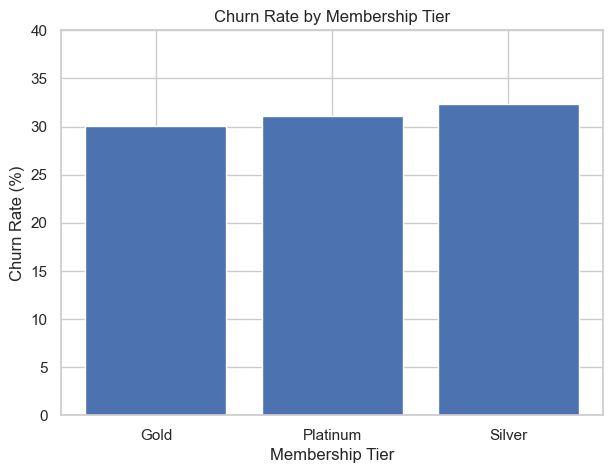

In [330]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    churn_by_tier["MEMBERSHIP_TIER"],
    churn_by_tier["churn_rate"]
)

plt.xlabel("Membership Tier")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Membership Tier")
plt.ylim(0, 40)

plt.show()

### Finding: Membership Tier

Observed churn rates are relatively similar across membership tiers:

- Gold: 30.10%
- Platinum: 31.13%
- Silver: 32.29%

Silver has the highest observed churn rate and Gold the lowest, but the difference is modest. Membership tier should therefore be evaluated alongside behavioural, engagement and support features rather than treated as a standalone churn driver.

In [331]:
churn_by_city = (
    customer_profile_clean
    .merge(
        churn_label_clean[["CUSTOMER_ID", "CHURNED"]],
        on="CUSTOMER_ID",
        how="inner"
    )
    .groupby("CITY")["CHURNED"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

churn_by_city["churn_rate"] *= 100

churn_by_city = churn_by_city.sort_values(
    "churn_rate",
    ascending=False
)

display(churn_by_city)

,CITY,customers,churned,churn_rate
0,Austin,266,100,37.593985
2,Columbus,268,97,36.194030
5,Nashville,237,79,33.333333
1,Boise,247,79,31.983806
9,Tulsa,295,88,29.830508
7,Raleigh,282,84,29.787234
4,Madison,256,76,29.687500
8,Spokane,252,73,28.968254
3,Denver,257,74,28.793774
6,Portland,240,68,28.333333


### Finding: City

Churn rates vary across cities more than they do across membership tiers.

The observed churn rate ranges from 28.33% in Portland to 37.59% in Austin. Austin and Columbus have the highest observed churn rates, while Portland, Denver and Spokane have lower observed rates.

These are descriptive differences and do not establish that location itself causes churn. City will be retained as a potential segmentation and predictive feature for further analysis.

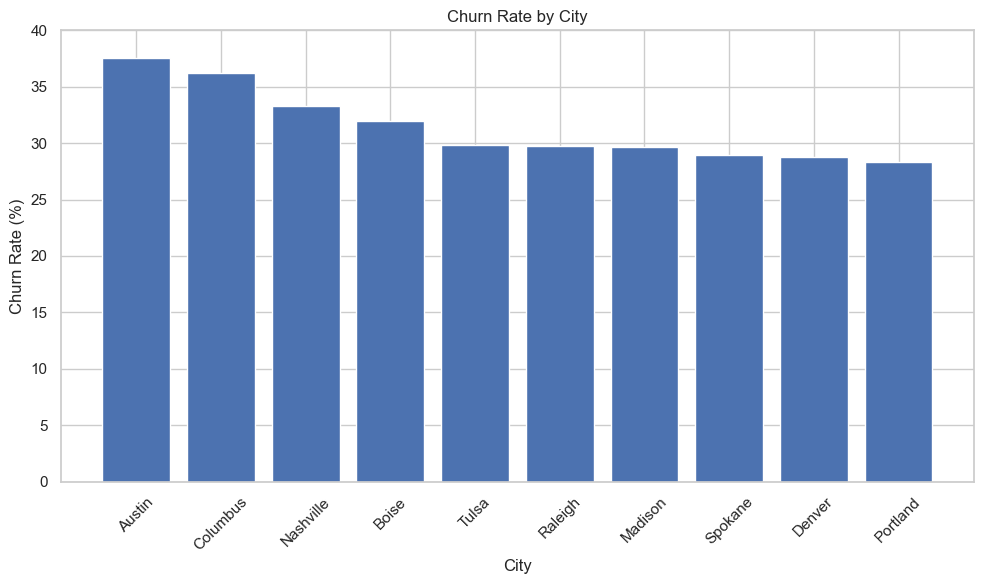

In [332]:
plt.figure(figsize=(10, 6))

plt.bar(
    churn_by_city["CITY"],
    churn_by_city["churn_rate"]
)

plt.xlabel("City")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by City")
plt.xticks(rotation=45)
plt.ylim(0, 40)

plt.tight_layout()
plt.show()

In [333]:
churn_by_gender = (
    customer_profile_clean
    .merge(
        churn_label_clean[["CUSTOMER_ID", "CHURNED"]],
        on="CUSTOMER_ID",
        how="inner"
    )
    .groupby("GENDER")["CHURNED"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

churn_by_gender["churn_rate"] *= 100

display(churn_by_gender)

,GENDER,customers,churned,churn_rate
0,F,1367,447,32.699342
1,M,1085,323,29.769585
2,Other,96,27,28.125000
3,Unknown,52,21,40.384615


### Finding: Gender

Observed churn rates differ across gender categories. Female customers have a churn rate of 32.70%, compared with 29.77% for male customers and 28.13% for the Other category.

The Unknown category has a higher observed churn rate of 40.38%, but it contains only 52 customers. Therefore, this value should be interpreted cautiously.

These differences are descriptive and do not establish gender as a causal driver of churn.

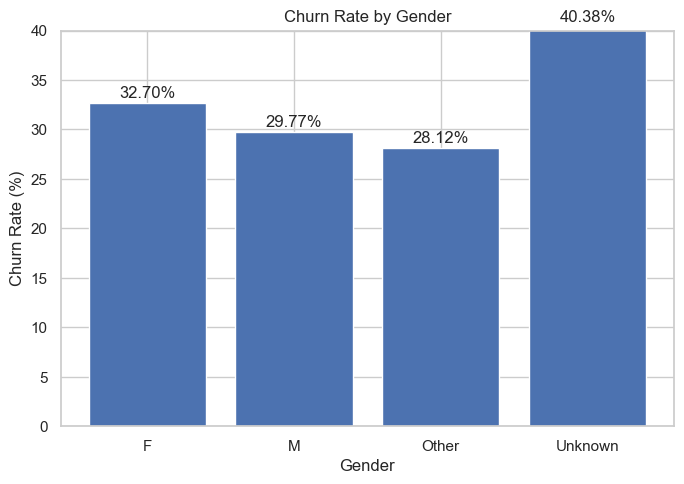

In [199]:
plt.figure(figsize=(7, 5))

plt.bar(
    churn_by_gender["GENDER"],
    churn_by_gender["churn_rate"]
)

plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.title("Churn Rate by Gender")

plt.ylim(0, 40)

for i, value in enumerate(churn_by_gender["churn_rate"]):
    plt.text(
        i,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [334]:
age_eda = (
    customer_profile_clean
    .merge(
        churn_label_clean[["CUSTOMER_ID", "CHURNED"]],
        on="CUSTOMER_ID",
        how="inner"
    )
)

age_eda["AGE_GROUP"] = pd.cut(
    age_eda["AGE"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
)

churn_by_age = (
    age_eda
    .groupby("AGE_GROUP", observed=True)["CHURNED"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

churn_by_age["churn_rate"] *= 100

display(churn_by_age)

,AGE_GROUP,customers,churned,churn_rate
0,18-25,327,99,30.275229
1,26-35,478,142,29.707113
2,36-45,437,138,31.578947
3,46-55,412,141,34.223301
4,56-65,471,146,30.997877
5,66+,397,128,32.241814


### Finding: Age

Churn rates are relatively similar across age groups, ranging from 29.71% for customers aged 26–35 to 34.22% for customers aged 46–55.

The 46–55 age group has the highest observed churn rate, while the 26–35 group has the lowest. Overall, the variation is modest, suggesting that age alone may provide limited separation between churned and retained customers.

Age should therefore be evaluated together with behavioural and engagement variables during modelling.

In [335]:
cohort_eda = (
    customer_profile_clean
    .merge(
        churn_label_clean[["CUSTOMER_ID", "CHURNED"]],
        on="CUSTOMER_ID",
        how="inner"
    )
)

cohort_eda["SIGNUP_YEAR"] = (
    pd.to_datetime(cohort_eda["SIGNUP_DATE"])
    .dt.year
)

churn_by_cohort = (
    cohort_eda
    .groupby("SIGNUP_YEAR")["CHURNED"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

churn_by_cohort["churn_rate"] *= 100

display(churn_by_cohort)

,SIGNUP_YEAR,customers,churned,churn_rate
0,2021,745,279,37.449664
1,2022,792,306,38.636364
2,2023,816,229,28.063725
3,2024,247,4,1.619433


### Finding: Signup Cohort

Churn rates differ substantially across signup cohorts. Customers who joined in 2021 and 2022 have observed churn rates of 37.45% and 38.64%, respectively, while the 2023 cohort has a lower rate of 28.06%.

The 2024 cohort has an observed churn rate of only 1.62%. However, this should not be interpreted as evidence of substantially lower underlying churn because the dataset ends in June 2024 and recent customers have shorter observation histories. The `INSUFFICIENT_HISTORY_FLAG` and `MONTHS_OBSERVED` variables should therefore be considered when interpreting cohort differences.

In [336]:
cohort_history = (
    cohort_eda
    .merge(
        churn_label_clean[
            ["CUSTOMER_ID", "INSUFFICIENT_HISTORY_FLAG", "MONTHS_OBSERVED"]
        ],
        on="CUSTOMER_ID",
        how="inner"
    )
    .groupby("SIGNUP_YEAR")
    .agg(
        customers=("CUSTOMER_ID", "count"),
        insufficient_history=("INSUFFICIENT_HISTORY_FLAG", "sum"),
        avg_months_observed=("MONTHS_OBSERVED", "mean")
    )
    .reset_index()
)

cohort_history["insufficient_history_pct"] = (
    cohort_history["insufficient_history"]
    / cohort_history["customers"]
    * 100
)

display(cohort_history)

,SIGNUP_YEAR,customers,insufficient_history,avg_months_observed,insufficient_history_pct
0,2021,745,68,13.693960,9.127517
1,2022,792,85,13.502525,10.732323
2,2023,816,94,9.129902,11.519608
3,2024,247,126,3.376518,51.012146


### Finding: Signup Cohort and Observation History

The 2024 signup cohort has substantially shorter observed histories than earlier cohorts. Its average number of observed months is 3.38, compared with 13.69 for 2021 and 13.50 for 2022.

Furthermore, 51.01% of customers who signed up in 2024 have the `INSUFFICIENT_HISTORY_FLAG` set, compared with approximately 9–12% for the 2021–2023 cohorts.

Therefore, the very low observed churn rate of 1.62% for the 2024 cohort should be interpreted cautiously. The difference may be strongly influenced by the shorter observation period and insufficient history rather than representing a directly comparable cohort-level churn difference.

In [337]:
activity_summary = (
    monthly_activity_clean
    .groupby("CUSTOMER_ID")
    .agg(
        total_transactions=("TRANSACTIONS", "sum"),
        total_spend=("TOTAL_SPEND", "sum"),
        avg_basket_value=("AVG_BASKET_VALUE", "mean"),
        avg_app_sessions=("APP_SESSIONS", "mean"),
        avg_emails_opened=("EMAILS_OPENED", "mean"),
        total_coupons_redeemed=("COUPONS_REDEEMED", "sum"),
        total_support_tickets=("SUPPORT_TICKETS", "sum"),
        avg_distinct_categories=("DISTINCT_CATEGORIES", "mean"),
        avg_promo_txn_pct=("PROMO_TXN_PCT", "mean"),
        complaint_rate=("COMPLAINT_FLAG", "mean")
    )
    .reset_index()
)

display(activity_summary.head())

,CUSTOMER_ID,total_transactions,total_spend,avg_basket_value,avg_app_sessions,avg_emails_opened,total_coupons_redeemed,total_support_tickets,avg_distinct_categories,avg_promo_txn_pct,complaint_rate
0,500001,79,1772.08,22.668235,2.176471,1.176471,7,3,2.705882,0.197059,0.058824
1,500002,71,2445.68,34.063333,2.583333,0.666667,8,3,2.250000,0.282500,0.000000
2,500003,84,2678.27,31.950588,3.294118,0.470588,11,2,2.705882,0.334706,0.058824
3,500004,84,1983.42,23.362941,3.823529,1.588235,9,5,3.705882,0.246471,0.058824
4,500005,0,0.00,0.000000,0.000000,0.000000,0,0,1.000000,0.000000,0.000000


In [338]:
behavior_eda = activity_summary.merge(
    churn_label_clean[["CUSTOMER_ID", "CHURNED"]],
    on="CUSTOMER_ID",
    how="left"
)

display(behavior_eda.head())

,CUSTOMER_ID,total_transactions,total_spend,avg_basket_value,avg_app_sessions,avg_emails_opened,total_coupons_redeemed,total_support_tickets,avg_distinct_categories,avg_promo_txn_pct,complaint_rate,CHURNED
0,500001,79,1772.08,22.668235,2.176471,1.176471,7,3,2.705882,0.197059,0.058824,0
1,500002,71,2445.68,34.063333,2.583333,0.666667,8,3,2.250000,0.282500,0.000000,0
2,500003,84,2678.27,31.950588,3.294118,0.470588,11,2,2.705882,0.334706,0.058824,0
3,500004,84,1983.42,23.362941,3.823529,1.588235,9,5,3.705882,0.246471,0.058824,0
4,500005,0,0.00,0.000000,0.000000,0.000000,0,0,1.000000,0.000000,0.000000,0


In [339]:
print("Rows:", len(behavior_eda))
print("Missing churn labels:", behavior_eda["CHURNED"].isna().sum())

Rows: 2594
Missing churn labels: 0


In [340]:
behavior_comparison = (
    behavior_eda
    .groupby("CHURNED")
    [
        [
            "total_transactions",
            "total_spend",
            "avg_basket_value",
            "avg_app_sessions",
            "avg_emails_opened",
            "total_coupons_redeemed",
            "total_support_tickets",
            "avg_distinct_categories",
            "avg_promo_txn_pct",
            "complaint_rate"
        ]
    ]
    .mean()
    .T
)

behavior_comparison.columns = [
    "Retained" if col == 0 else "Churned"
    for col in behavior_comparison.columns
]

display(behavior_comparison)

,Retained,Churned
total_transactions,56.718223,19.568627
total_spend,1837.037637,625.241489
avg_basket_value,28.961841,24.727456
avg_app_sessions,2.124027,1.070644
avg_emails_opened,1.039906,0.666207
total_coupons_redeemed,7.365579,3.254902
total_support_tickets,1.587177,1.888480
avg_distinct_categories,2.478354,1.806941
avg_promo_txn_pct,0.256109,0.238492
complaint_rate,0.044920,0.076423


### Finding: Behavioural Differences Between Retained and Churned Customers

The behavioural comparison shows substantial differences between retained and churned customers.

Churned customers have substantially lower purchasing activity, with average total transactions of 19.57 compared with 56.72 for retained customers, and average total spend of 625.24 compared with 1,837.04.

Engagement is also lower among churned customers. Average app sessions are 1.07 compared with 2.12 for retained customers, while average emails opened are 0.67 compared with 1.04.

Churned customers also redeem fewer coupons and interact with fewer distinct product categories. In contrast, support tickets and complaint rates are somewhat higher among churned customers.

Promo transaction percentage is relatively similar between the two groups.

These are observed group-level differences and should not be interpreted as causal effects. The variables will be evaluated using leakage-safe feature engineering and predictive modelling.

<Figure size 700x500 with 0 Axes>

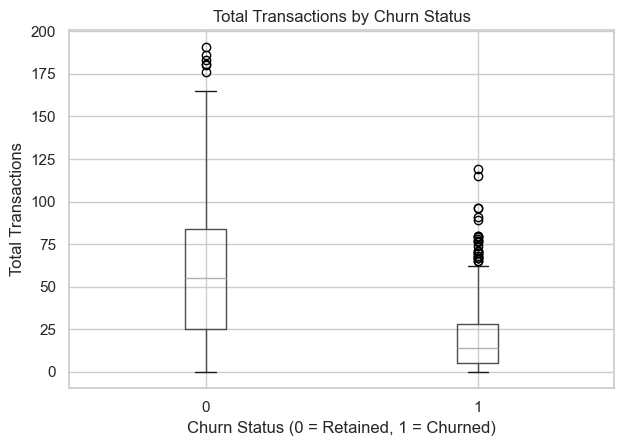

In [341]:
plt.figure(figsize=(7, 5))

behavior_eda.boxplot(
    column="total_transactions",
    by="CHURNED"
)

plt.title("Total Transactions by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status (0 = Retained, 1 = Churned)")
plt.ylabel("Total Transactions")

plt.tight_layout()
plt.show()

### Finding: Total Transactions

The distribution of total transactions differs substantially between retained and churned customers. Retained customers generally have higher transaction counts, with a much higher median than churned customers.

Although there is some overlap between the groups and both contain outliers, the overall distribution indicates that lower purchasing frequency is strongly associated with observed churn.

This variable is therefore a potentially important predictive feature, subject to leakage-safe feature construction during modelling.

<Figure size 700x500 with 0 Axes>

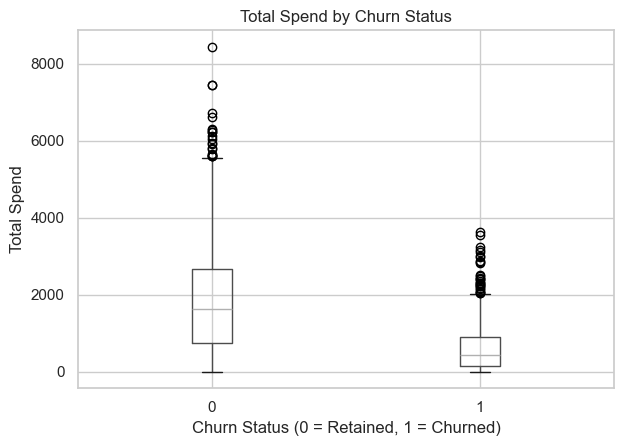

In [ ]:
plt.figure(figsize=(7, 5))

behavior_eda.boxplot(
    column="total_spend",
    by="CHURNED"
)

plt.title("Total Spend by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status (0 = Retained, 1 = Churned)")
plt.ylabel("Total Spend")

plt.tight_layout()
plt.show()

### Finding: Total Spend

Total spend shows a substantial difference between retained and churned customers. Retained customers generally have a much higher spend distribution and median spend than churned customers.

Both groups contain high-spend outliers, with a wider upper tail among retained customers. The distribution supports the earlier finding that churned customers generally exhibit lower purchasing activity and monetary value.

Total spend may therefore provide useful predictive information, subject to leakage-safe feature construction during modelling.

<Figure size 700x500 with 0 Axes>

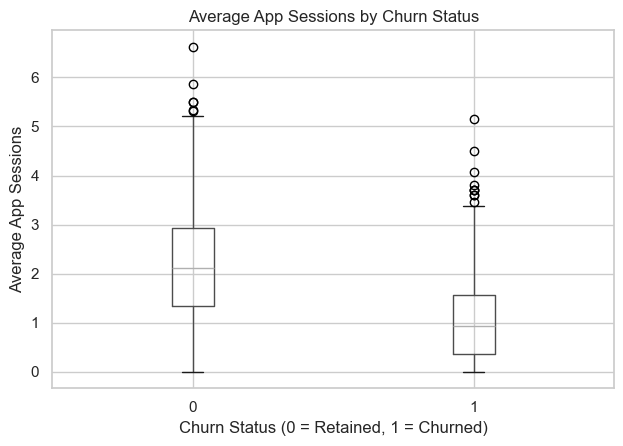

In [343]:
plt.figure(figsize=(7, 5))

behavior_eda.boxplot(
    column="avg_app_sessions",
    by="CHURNED"
)

plt.title("Average App Sessions by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status (0 = Retained, 1 = Churned)")
plt.ylabel("Average App Sessions")

plt.tight_layout()
plt.show()

### Finding: App Engagement

Average app sessions are lower among churned customers than retained customers. The boxplot shows a lower median and overall distribution for churned customers, indicating that reduced app engagement is associated with observed churn.

This suggests that engagement-related variables may add predictive information beyond demographic characteristics.

In [344]:
churn_by_complaint = (
    customer_profile_clean
    .merge(
        monthly_activity_clean[
            ["CUSTOMER_ID", "COMPLAINT_FLAG"]
        ]
        .groupby("CUSTOMER_ID")["COMPLAINT_FLAG"]
        .mean()
        .reset_index(),
        on="CUSTOMER_ID",
        how="left"
    )
    .merge(
        churn_label_clean[["CUSTOMER_ID", "CHURNED"]],
        on="CUSTOMER_ID",
        how="inner"
    )
)

churn_by_complaint["HAS_COMPLAINT"] = (
    churn_by_complaint["COMPLAINT_FLAG"] > 0
).astype(int)

complaint_comparison = (
    churn_by_complaint
    .groupby("HAS_COMPLAINT")["CHURNED"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

complaint_comparison["churn_rate"] *= 100

display(complaint_comparison)

,HAS_COMPLAINT,customers,churned,churn_rate
0,0,1661,502,30.222757
1,1,939,316,33.652822


In [345]:
marketing_comparison = (
    customer_profile_clean
    .merge(
        churn_label_clean[["CUSTOMER_ID", "CHURNED"]],
        on="CUSTOMER_ID",
        how="inner"
    )
    .groupby("MARKETING_OPT_IN")["CHURNED"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

marketing_comparison["churn_rate"] *= 100

display(marketing_comparison)

,MARKETING_OPT_IN,customers,churned,churn_rate
0,0,1008,350,34.722222
1,1,1592,468,29.396985


### Finding: Complaint and Marketing Engagement

Customers with at least one recorded complaint have an observed churn rate of 33.65%, compared with 30.22% among customers without complaints.

Marketing opt-in shows a larger observed difference. Customers who are not opted in have a churn rate of 34.72%, compared with 29.40% for customers who are opted in.

These relationships suggest that customer experience and engagement variables may provide additional predictive information. However, the observed differences do not establish causal relationships.

In [346]:
numeric_eda = behavior_eda[
    [
        "total_transactions",
        "total_spend",
        "avg_basket_value",
        "avg_app_sessions",
        "avg_emails_opened",
        "total_coupons_redeemed",
        "total_support_tickets",
        "avg_distinct_categories",
        "avg_promo_txn_pct",
        "complaint_rate",
        "CHURNED"
    ]
]

spearman_corr = (
    numeric_eda
    .corr(method="spearman")["CHURNED"]
    .drop("CHURNED")
    .sort_values()
)

display(spearman_corr.to_frame("spearman_correlation"))

,spearman_correlation
total_transactions,-0.467534
total_spend,-0.456612
avg_app_sessions,-0.432688
total_coupons_redeemed,-0.424638
avg_distinct_categories,-0.359842
avg_emails_opened,-0.266025
avg_basket_value,-0.242845
avg_promo_txn_pct,-0.159955
total_support_tickets,0.100224
complaint_rate,0.102756


# EDA Summary and Key Findings

## 1. Churn Distribution

The dataset contains 2,605 labelled customers after removing duplicate churn-label records. Of these, 821 customers (31.52%) are labelled as churned and 1,784 (68.48%) as retained.

The target therefore has moderate class imbalance, which should be considered during model training and evaluation.

## 2. Membership Tier

Observed churn rates are relatively similar across membership tiers:

- Gold: 30.10%
- Platinum: 31.13%
- Silver: 32.29%

The differences are modest, suggesting that membership tier alone provides limited separation of churn risk.

## 3. City

Observed churn rates vary across cities, ranging from approximately 28.33% to 37.59%.

These differences represent descriptive geographic variation and do not establish that location itself causes churn.

## 4. Gender

Observed churn rates were:

- Female: 32.70%
- Male: 29.77%
- Other: 28.13%
- Unknown: 40.38%

The Unknown category contains only 52 customers and should therefore be interpreted cautiously.

## 5. Age

Churn rates were relatively similar across age groups, ranging from 29.71% to 34.22%.

The 46–55 group had the highest observed rate, while the 26–35 group had the lowest. Overall, age showed less separation than several behavioural variables.

## 6. Signup Cohort

Signup cohort showed substantial differences in observed churn:

- 2021: 37.45%
- 2022: 38.64%
- 2023: 28.06%
- 2024: 1.62%

The 2024 result requires caution because 51.01% of the 2024 cohort has insufficient history and its average observation period is only 3.38 months. Therefore, the low observed churn rate should not be interpreted as directly comparable with earlier cohorts.

## 7. Behavioural Differences

Churned customers showed substantially lower purchasing and engagement activity than retained customers.

Examples include:

- Total transactions: 19.57 vs 56.72
- Total spend: 625.24 vs 1,837.04
- Average app sessions: 1.07 vs 2.12
- Coupons redeemed: 3.25 vs 7.37
- Distinct categories: 1.81 vs 2.48

Churned customers also had somewhat higher support-ticket activity and complaint rates.

## 8. Marketing and Complaint Behaviour

Customers with at least one complaint had an observed churn rate of 33.65%, compared with 30.22% for customers without complaints.

Customers without marketing opt-in had an observed churn rate of 34.72%, compared with 29.40% among customers who opted in.

These are observed associations and should not be interpreted as causal effects.

## 9. Correlation Analysis

Spearman correlation showed the strongest negative associations with churn for:

- Total transactions: -0.468
- Total spend: -0.457
- App sessions: -0.433
- Coupons redeemed: -0.425
- Distinct categories: -0.360

Support tickets and complaint rate had weak positive associations with churn.

Overall, behavioural and engagement variables showed stronger descriptive relationships with churn than basic demographic variables.

## Overall EDA Conclusion

The EDA indicates that customer purchasing frequency, monetary activity and engagement are important candidate predictors of churn. Demographic and segmentation variables such as membership tier, city, gender and age show smaller or more variable differences.

These findings will guide feature engineering and modelling. However, all predictive features must be constructed using information available before the April–June 2024 churn-label window to prevent target leakage.